In [2]:
from pathlib import Path

# Define the project data paths
data_dir = Path("../data/raw")

zip_path = data_dir / "online_retail.zip"
excel_path = data_dir / "Online Retail.xlsx"

# Check whether the downloaded files exist
print("ZIP file exists:", zip_path.exists())
print("Excel file exists:", excel_path.exists())

ZIP file exists: True
Excel file exists: True


In [3]:
import pandas as pd

# Define the path to the Excel dataset
file_path = "../data/raw/Online Retail.xlsx"

# Load the Excel file into a pandas DataFrame
df = pd.read_excel(file_path)

# Display a confirmation message
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 541909
Number of columns: 8


In [5]:
# Display the column names and their data types
print("Column names and data types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values in each column:")
print(df.isnull().sum())

Column names and data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [6]:
# Check for negative and zero quantities
print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Zero quantities:", (df["Quantity"] == 0).sum())

# Check for negative and zero unit prices
print("Negative unit prices:", (df["UnitPrice"] < 0).sum())
print("Zero unit prices:", (df["UnitPrice"] == 0).sum())

# Check for cancellation invoices
print("Invoice numbers starting with C:",
      df["InvoiceNo"].astype(str).str.startswith("C").sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Negative quantities:

 10624
Zero quantities: 0
Negative unit prices: 2
Zero unit prices: 2515
Invoice numbers starting with C: 9288
Duplicate rows: 5268


In [7]:
# 1. Inspect rows with negative quantities
display(df[df["Quantity"] < 0].head(10))

# 2. Inspect rows with negative unit prices
display(df[df["UnitPrice"] < 0])

# 3. Inspect rows with zero unit prices
display(df[df["UnitPrice"] == 0].head(10))

# 4. Inspect cancellation invoices
display(
    df[df["InvoiceNo"].astype(str).str.startswith("C")].head(10)
)

# 5. Inspect duplicate records
display(df[df.duplicated(keep=False)].head(10))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [8]:
# Inspect zero-price records
zero_price = df[df["UnitPrice"] == 0]

print("Total zero-price records:", len(zero_price))
print("\nMost common zero-price descriptions:")
display(zero_price["Description"].value_counts().head(15))

# Check whether cancellation invoices have negative quantities
cancellations = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
]

print("\nCancellation invoice rows:", len(cancellations))
print(
    "Cancellation rows with negative quantities:",
    (cancellations["Quantity"] < 0).sum()
)

# Check exact duplicates
print("\nExact duplicate rows:", df.duplicated().sum())

Total zero-price records: 2515

Most common zero-price descriptions:


Description
check                            159
?                                 47
damages                           45
damaged                           43
found                             25
sold as set on dotcom             20
adjustment                        16
Damaged                           14
FRENCH BLUE METAL DOOR SIGN 1      9
thrown away                        9
Unsaleable, destroyed.             9
amazon                             8
FRENCH BLUE METAL DOOR SIGN 8      8
Found                              8
FRENCH BLUE METAL DOOR SIGN 4      7
Name: count, dtype: int64


Cancellation invoice rows: 9288
Cancellation rows with negative quantities: 9288

Exact duplicate rows: 5268


In [9]:
# Keep a copy of the original dataset
df_clean = df.copy()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Keep only rows with a known customer ID
df_clean = df_clean.dropna(subset=["CustomerID"])

# Exclude cancellation invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Keep only positive quantities and positive unit prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
]

# Create a revenue column
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Display the results
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

print("\nRemaining negative quantities:",
      (df_clean["Quantity"] < 0).sum())

print("Remaining non-positive unit prices:",
      (df_clean["UnitPrice"] <= 0).sum())

print("\nCleaned dataset preview:")
display(df_clean.head())

Original rows: 541909
Cleaned rows: 392692
Rows removed: 149217

Remaining missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
dtype: int64

Remaining negative quantities: 0
Remaining non-positive unit prices: 0

Cleaned dataset preview:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [10]:
# Keep a copy of the original dataset
df_clean = df.copy()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Keep only rows with a known customer ID
df_clean = df_clean.dropna(subset=["CustomerID"])

# Exclude cancellation invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Keep only positive quantities and positive unit prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
]

# Create a revenue column
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Display the results
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

print("\nRemaining negative quantities:",
      (df_clean["Quantity"] < 0).sum())

print("Remaining non-positive unit prices:",
      (df_clean["UnitPrice"] <= 0).sum())

print("\nCleaned dataset preview:")
display(df_clean.head())

Original rows: 541909
Cleaned rows: 392692
Rows removed: 149217

Remaining missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
dtype: int64

Remaining negative quantities: 0
Remaining non-positive unit prices: 0

Cleaned dataset preview:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [11]:
# Basic dataset validation
print("Cleaned dataset shape:", df_clean.shape)

print(
    "Unique customers:",
    df_clean["CustomerID"].nunique()
)

print(
    "Unique invoices:",
    df_clean["InvoiceNo"].nunique()
)

print(
    "Unique products:",
    df_clean["StockCode"].nunique()
)

print(
    "Date range:",
    df_clean["InvoiceDate"].min(),
    "to",
    df_clean["InvoiceDate"].max()
)

print(
    "Total revenue:",
    round(df_clean["Revenue"].sum(), 2)
)

print(
    "Remaining exact duplicates:",
    df_clean.duplicated().sum()
)

Cleaned dataset shape: (392692, 9)
Unique customers: 4338
Unique invoices: 18532
Unique products: 3665
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Total revenue: 8887208.89
Remaining exact duplicates: 0


YearMonth
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517190.440
Freq: M, Name: Revenue, dtype: float64

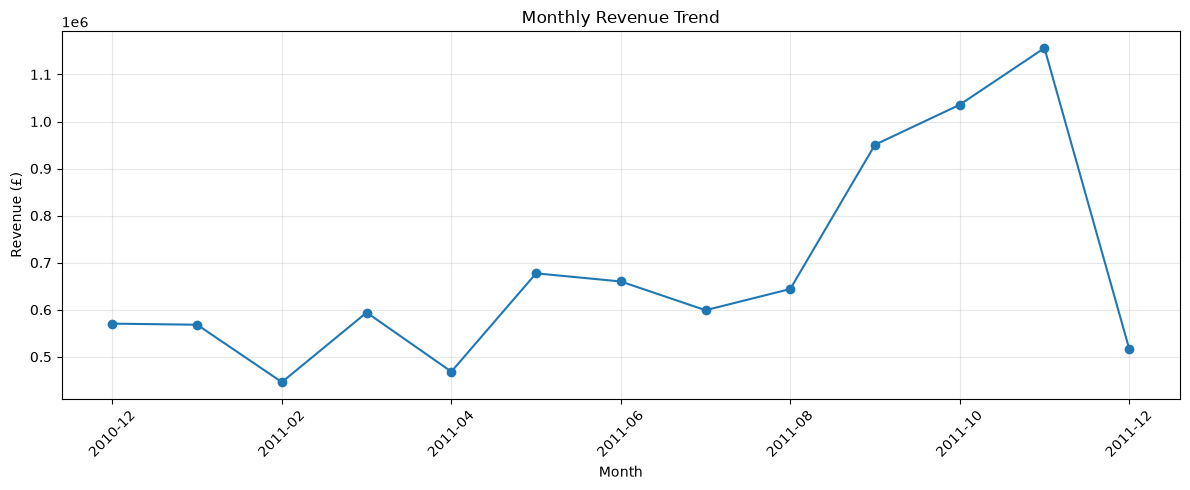

In [12]:
import matplotlib.pyplot as plt

# Extract the year and month from each invoice date
df_clean["YearMonth"] = (
    df_clean["InvoiceDate"].dt.to_period("M")
)

# Calculate monthly revenue
monthly_revenue = (
    df_clean.groupby("YearMonth")["Revenue"]
    .sum()
    .sort_index()
)

# Display the monthly revenue values
display(monthly_revenue)

# Plot monthly revenue
plt.figure(figsize=(12, 5))
monthly_revenue.index = monthly_revenue.index.astype(str)

monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
# Summarize purchasing behavior for each customer
customer_summary = (
    df_clean.groupby("CustomerID")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        TotalOrders=("InvoiceNo", "nunique"),
        TotalQuantity=("Quantity", "sum"),
        FirstPurchase=("InvoiceDate", "min"),
        LastPurchase=("InvoiceDate", "max")
    )
)

# Identify repeat customers
customer_summary["IsRepeatCustomer"] = (
    customer_summary["TotalOrders"] > 1
)

# Calculate customer statistics
total_customers = len(customer_summary)
repeat_customers = customer_summary["IsRepeatCustomer"].sum()

repeat_rate = repeat_customers / total_customers * 100

print("Total customers:", total_customers)
print("Repeat customers:", repeat_customers)
print("One-time customers:", total_customers - repeat_customers)
print(f"Repeat customer rate: {repeat_rate:.2f}%")

print(
    "\nAverage revenue per customer:",
    round(customer_summary["TotalRevenue"].mean(), 2)
)

print(
    "Average number of orders per customer:",
    round(customer_summary["TotalOrders"].mean(), 2)
)

# Display the 10 highest-revenue customers
display(
    customer_summary.sort_values(
        "TotalRevenue", ascending=False
    ).head(10)
)

Total customers: 4338
Repeat customers: 2845
One-time customers: 1493
Repeat customer rate: 65.58%

Average revenue per customer: 2048.69
Average number of orders per customer: 4.27


,TotalRevenue,TotalOrders,TotalQuantity,FirstPurchase,LastPurchase,IsRepeatCustomer
CustomerID,,,,,,
14646.0,280206.02,73,196915,2010-12-20 10:09:00,2011-12-08 12:12:00,True
18102.0,259657.30,60,64124,2010-12-07 16:42:00,2011-12-09 11:50:00,True
17450.0,194390.79,46,69973,2010-12-07 09:23:00,2011-12-01 13:29:00,True
16446.0,168472.50,2,80997,2011-05-18 09:52:00,2011-12-09 09:15:00,True
14911.0,143711.17,201,80240,2010-12-01 14:05:00,2011-12-08 15:54:00,True
12415.0,124914.53,21,77374,2011-01-06 11:12:00,2011-11-15 14:22:00,True
14156.0,117210.08,55,57768,2010-12-03 11:48:00,2011-11-30 10:54:00,True
17511.0,91062.38,31,64549,2010-12-01 10:19:00,2011-12-07 10:12:00,True
16029.0,80850.84,63,40108,2010-12-01 09:57:00,2011-11-01 10:27:00,True


In [14]:
# Set the reference date to one day after the last recorded transaction
reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate RFM metrics for each customer
rfm = (
    df_clean.groupby("CustomerID")
    .agg(
        Recency=("InvoiceDate", lambda dates:
                 (reference_date - dates.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum")
    )
)

print("Reference date:", reference_date)
print("RFM dataset shape:", rfm.shape)

display(rfm.head(10))

print("\nRFM summary statistics:")
display(rfm.describe().round(2))

Reference date: 2011-12-10 12:50:00
RFM dataset shape: (4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40
12352.0,36,8,2506.04
12353.0,204,1,89.00
12354.0,232,1,1079.40
12355.0,214,1,459.40



RFM summary statistics:


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02


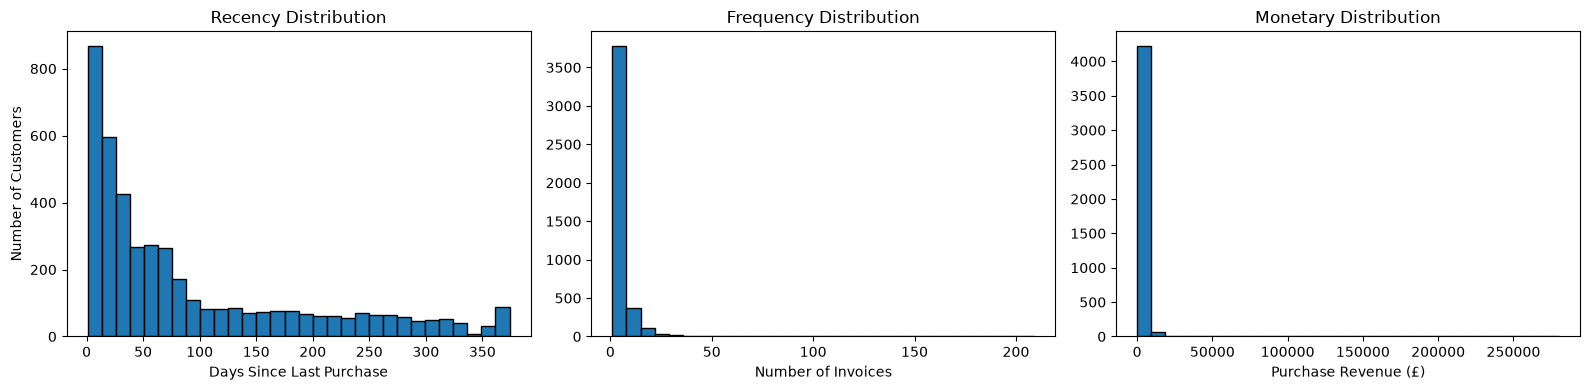

In [15]:
import matplotlib.pyplot as plt

# Plot the distributions of the three RFM metrics
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(rfm["Recency"], bins=30, edgecolor="black")
axes[0].set_title("Recency Distribution")
axes[0].set_xlabel("Days Since Last Purchase")
axes[0].set_ylabel("Number of Customers")

axes[1].hist(rfm["Frequency"], bins=30, edgecolor="black")
axes[1].set_title("Frequency Distribution")
axes[1].set_xlabel("Number of Invoices")

axes[2].hist(rfm["Monetary"], bins=30, edgecolor="black")
axes[2].set_title("Monetary Distribution")
axes[2].set_xlabel("Purchase Revenue (£)")

plt.tight_layout()
plt.show()

In [16]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# Copy the original RFM data
rfm_model = rfm.copy()

# Log-transform the skewed features
rfm_log = np.log1p(rfm_model[["Recency", "Frequency", "Monetary"]])

# Standardize the transformed features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Convert back to a DataFrame for easier inspection
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    index=rfm.index,
    columns=["Recency", "Frequency", "Monetary"]
)

print("Scaled dataset shape:", rfm_scaled.shape)

print("\nScaled feature means (approximately 0):")
print(rfm_scaled.mean().round(3))

print("\nScaled feature standard deviations (approximately 1):")
print(rfm_scaled.std(ddof=0).round(3))

display(rfm_scaled.head())

Scaled dataset shape: (4338, 3)

Scaled feature means (approximately 0):
Recency     -0.0
Frequency   -0.0
Monetary    -0.0
dtype: float64

Scaled feature standard deviations (approximately 1):
Recency      1.0
Frequency    1.0
Monetary     1.0
dtype: float64


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,1.461993,-0.955214,3.707716
12347.0,-2.038734,1.074425,1.414903
12348.0,0.373104,0.386304,0.720024
12349.0,-0.623086,-0.955214,0.702287
12350.0,1.424558,-0.955214,-0.614514


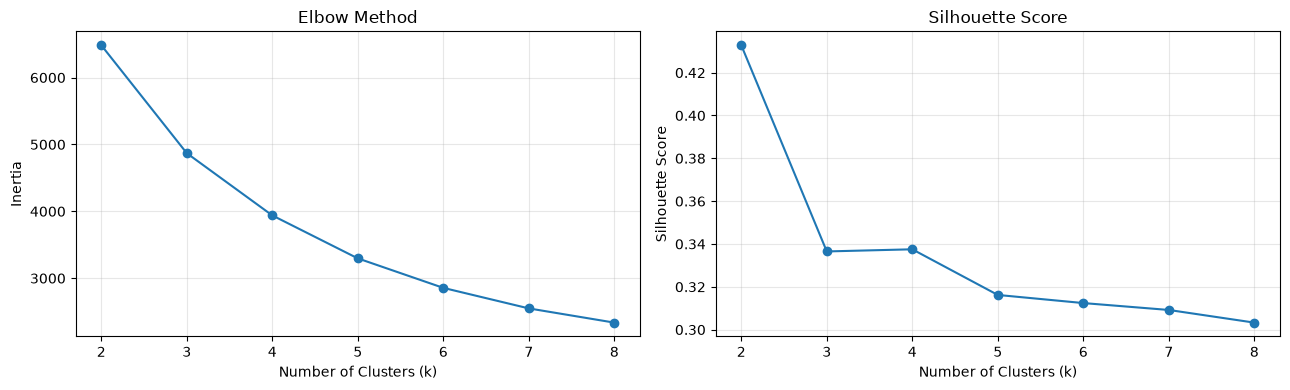

k=2: Inertia=6483.59, Silhouette=0.4328
k=3: Inertia=4869.49, Silhouette=0.3365
k=4: Inertia=3939.05, Silhouette=0.3375
k=5: Inertia=3296.71, Silhouette=0.3162
k=6: Inertia=2855.76, Silhouette=0.3124
k=7: Inertia=2548.82, Silhouette=0.3092
k=8: Inertia=2336.34, Silhouette=0.3033


In [17]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test between 2 and 8 customer segments
cluster_range = range(2, 9)

inertia_values = []
silhouette_values = []

for k in cluster_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(rfm_scaled)

    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(
        silhouette_score(rfm_scaled, cluster_labels)
    )

# Plot both evaluation metrics
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    list(cluster_range), inertia_values, marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    list(cluster_range), silhouette_values, marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Display the exact values
for k, inertia, silhouette in zip(
    cluster_range, inertia_values, silhouette_values
):
    print(
        f"k={k}: Inertia={inertia:.2f}, "
        f"Silhouette={silhouette:.4f}"
    )

In [18]:
# Train the selected K-Means model
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Assign each customer to a cluster
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

# Summarize the original RFM metrics by cluster
cluster_summary = rfm.groupby("Cluster").agg(
    CustomerCount=("Recency", "size"),
    AvgRecency=("Recency", "mean"),
    MedianRecency=("Recency", "median"),
    AvgFrequency=("Frequency", "mean"),
    MedianFrequency=("Frequency", "median"),
    AvgMonetary=("Monetary", "mean"),
    MedianMonetary=("Monetary", "median")
).round(2)

# Calculate the percentage of customers in each cluster
cluster_summary["CustomerPercentage"] = (
    cluster_summary["CustomerCount"] / len(rfm) * 100
).round(2)

display(cluster_summary)

,CustomerCount,AvgRecency,MedianRecency,AvgFrequency,MedianFrequency,AvgMonetary,MedianMonetary,CustomerPercentage
Cluster,,,,,,,,
0,713,12.17,8.0,13.75,10.0,8088.02,3722.82,16.44
1,1622,181.51,174.5,1.32,1.0,341.00,296.09,37.39
2,837,17.70,17.0,2.19,2.0,557.32,480.31,19.29
3,1166,71.64,57.0,4.08,4.0,1801.78,1345.20,26.88


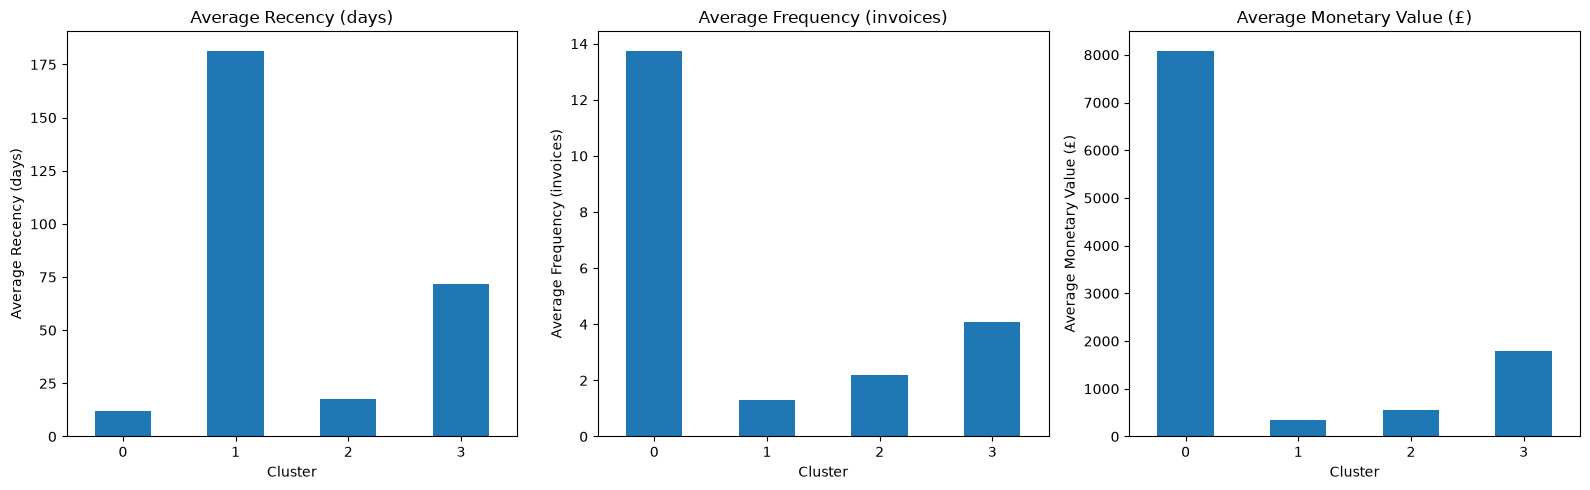

In [19]:
import matplotlib.pyplot as plt

metrics = [
    ("Recency", "Average Recency (days)"),
    ("Frequency", "Average Frequency (invoices)"),
    ("Monetary", "Average Monetary Value (£)")
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (metric, title) in zip(axes, metrics):
    cluster_means = rfm.groupby("Cluster")[metric].mean()

    cluster_means.plot(kind="bar", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Cluster")
    ax.set_ylabel(title)
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [20]:
from pathlib import Path

# Create the processed-data folder if it doesn't exist
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Save the customer-level RFM data and cluster assignments
output_path = processed_dir / "customer_rfm_segments.csv"

rfm.to_csv(output_path, index=True)

print("Saved customer segmentation to:", output_path)
print("Customers saved:", len(rfm))
print("Clusters:", sorted(rfm["Cluster"].unique()))
print("File exists:", output_path.exists())

Saved customer segmentation to: ..\data\processed\customer_rfm_segments.csv
Customers saved: 4338
Clusters: [np.int32(0), np.int32(1), np.int32(2), np.int32(3)]
File exists: True


In [21]:
# Create a business-friendly summary of the segments
segment_summary = rfm.groupby("Cluster").agg(
    CustomerCount=("Recency", "size"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean")
).round(2)

segment_summary["CustomerPercentage"] = (
    segment_summary["CustomerCount"] / len(rfm) * 100
).round(2)

# Add business-friendly labels based on the profiles
segment_names = {
    0: "Recent High-Value Customers",
    1: "At-Risk / Inactive Customers",
    2: "Recent Developing Customers",
    3: "Established Customers"
}

segment_summary["SegmentName"] = segment_summary.index.map(
    segment_names
)

# Display and save the summary
display(segment_summary)

segment_summary.to_csv(
    "../data/processed/customer_segment_summary.csv",
    index=True
)

print("Segment summary saved successfully.")

,CustomerCount,AvgRecency,AvgFrequency,AvgMonetary,CustomerPercentage,SegmentName
Cluster,,,,,,
0,713,12.17,13.75,8088.02,16.44,Recent High-Value Customers
1,1622,181.51,1.32,341.00,37.39,At-Risk / Inactive Customers
2,837,17.70,2.19,557.32,19.29,Recent Developing Customers
3,1166,71.64,4.08,1801.78,26.88,Established Customers


Segment summary saved successfully.


In [22]:
# Inspect the transaction date range
print("First transaction:", df_clean["InvoiceDate"].min())
print("Last transaction:", df_clean["InvoiceDate"].max())

# Count distinct invoices by month
monthly_invoices = (
    df_clean.assign(
        YearMonth=df_clean["InvoiceDate"].dt.to_period("M")
    )
    .groupby("YearMonth")["InvoiceNo"]
    .nunique()
)

display(monthly_invoices)

First transaction: 2010-12-01 08:26:00
Last transaction: 2011-12-09 12:50:00


YearMonth
2010-12    1400
2011-01     987
2011-02     997
2011-03    1321
2011-04    1149
2011-05    1555
2011-06    1393
2011-07    1331
2011-08    1280
2011-09    1755
2011-10    1929
2011-11    2657
2011-12     778
Freq: M, Name: InvoiceNo, dtype: int64

In [23]:
import pandas as pd

# Define the historical feature window and 90-day prediction window
cutoff_date = pd.Timestamp("2011-09-01")
prediction_end = cutoff_date + pd.Timedelta(days=90)

# Transactions available before the cutoff
historical_data = df_clean[
    df_clean["InvoiceDate"] < cutoff_date
].copy()

# Transactions during the 90-day prediction window
future_data = df_clean[
    (df_clean["InvoiceDate"] >= cutoff_date) &
    (df_clean["InvoiceDate"] < prediction_end)
].copy()

print("Feature window starts:", df_clean["InvoiceDate"].min())
print("Feature cutoff:", cutoff_date)
print("Prediction window ends (exclusive):", prediction_end)

print("\nHistorical transaction rows:", len(historical_data))
print("Historical unique customers:",
      historical_data["CustomerID"].nunique())

print("\nFuture transaction rows:", len(future_data))
print("Future unique customers:",
      future_data["CustomerID"].nunique())

Feature window starts: 2010-12-01 08:26:00
Feature cutoff: 2011-09-01 00:00:00
Prediction window ends (exclusive): 2011-11-30 00:00:00

Historical transaction rows: 224036
Historical unique customers: 3317

Future transaction rows: 149526
Future unique customers: 2839


In [24]:
# Build historical customer features
customer_features = (
    historical_data.groupby("CustomerID")
    .agg(
        HistoricalOrders=("InvoiceNo", "nunique"),
        HistoricalRevenue=("Revenue", "sum"),
        HistoricalQuantity=("Quantity", "sum"),
        FirstPurchase=("InvoiceDate", "min"),
        LastPurchase=("InvoiceDate", "max")
    )
)

# Calculate average revenue per historical invoice
customer_features["AverageOrderValue"] = (
    customer_features["HistoricalRevenue"] /
    customer_features["HistoricalOrders"]
)

# Calculate recency at the prediction cutoff
customer_features["Recency"] = (
    cutoff_date - customer_features["LastPurchase"]
).dt.days

# Identify customers who purchased during the future window
future_customer_ids = set(future_data["CustomerID"].unique())

customer_features["RepeatPurchase"] = (
    customer_features.index.isin(future_customer_ids)
).astype(int)

# Display the dataset summary
print("Customers available for modeling:", len(customer_features))
print("\nTarget distribution:")
print(customer_features["RepeatPurchase"].value_counts())

print("\nTarget percentages:")
print(
    (customer_features["RepeatPurchase"].value_counts(normalize=True) * 100)
    .round(2)
)

display(customer_features.head())

Customers available for modeling: 3317

Target distribution:
RepeatPurchase
1    1864
0    1453
Name: count, dtype: int64

Target percentages:
RepeatPurchase
1    56.2
0    43.8
Name: proportion, dtype: float64


,HistoricalOrders,HistoricalRevenue,HistoricalQuantity,FirstPurchase,LastPurchase,AverageOrderValue,Recency,RepeatPurchase
CustomerID,,,,,,,,
12346.0,1,77183.60,74215,2011-01-18 10:01:00,2011-01-18 10:01:00,77183.600000,225,0
12347.0,5,2790.86,1590,2010-12-07 14:57:00,2011-08-02 08:48:00,558.172000,29,1
12348.0,3,1487.24,2124,2010-12-16 19:09:00,2011-04-05 10:47:00,495.746667,148,1
12350.0,1,334.40,197,2011-02-02 16:01:00,2011-02-02 16:01:00,334.400000,210,0
12352.0,5,1561.81,254,2011-02-16 12:33:00,2011-03-22 16:08:00,312.362000,162,1


In [25]:
from sklearn.model_selection import train_test_split

# Select only numeric historical features
feature_columns = [
    "HistoricalOrders",
    "HistoricalRevenue",
    "HistoricalQuantity",
    "AverageOrderValue",
    "Recency"
]

X = customer_features[feature_columns]
y = customer_features["RepeatPurchase"]

# Split data while preserving target proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)

print("\nTraining target percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTest target percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

print("\nMissing values in training features:")
print(X_train.isnull().sum())

Training features: (2653, 5)
Test features: (664, 5)

Training target percentages:
RepeatPurchase
1    56.2
0    43.8
Name: proportion, dtype: float64

Test target percentages:
RepeatPurchase
1    56.17
0    43.83
Name: proportion, dtype: float64

Missing values in training features:
HistoricalOrders      0
HistoricalRevenue     0
HistoricalQuantity    0
AverageOrderValue     0
Recency               0
dtype: int64


In [26]:
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression

# Build a machine learning pipeline
logistic_model = Pipeline([
    ("log_transform", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

# Train the model using training data only
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predict customer outcomes
y_pred = logistic_model.predict(X_test)

# Predict probabilities of repeat purchase
y_proba = logistic_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("MODEL EVALUATION")
print("-" * 40)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Repeat Purchase", "Repeat Purchase"]
))

MODEL EVALUATION
----------------------------------------
Accuracy:  0.6792
Precision: 0.7210
Recall:    0.6997
F1-score:  0.7102
ROC-AUC:   0.7322

Confusion Matrix:
[[190 101]
 [112 261]]

Classification Report:
                    precision    recall  f1-score   support

No Repeat Purchase       0.63      0.65      0.64       291
   Repeat Purchase       0.72      0.70      0.71       373

          accuracy                           0.68       664
         macro avg       0.68      0.68      0.68       664
      weighted avg       0.68      0.68      0.68       664



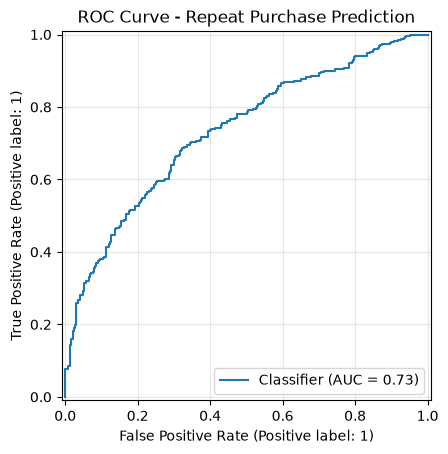

In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# Plot ROC curve
RocCurveDisplay.from_predictions(y_test, y_proba)

plt.title("ROC Curve - Repeat Purchase Prediction")
plt.grid(alpha=0.3)
plt.show()

In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train on the original training features
rf_model.fit(X_train, y_train)

# Predict classes and probabilities
rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

# Evaluate performance
print("RANDOM FOREST EVALUATION")
print("-" * 40)
print(f"Accuracy:  {accuracy_score(y_test, rf_pred):.4f}")
print(f"Precision: {precision_score(y_test, rf_pred):.4f}")
print(f"Recall:    {recall_score(y_test, rf_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, rf_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, rf_proba):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

RANDOM FOREST EVALUATION
----------------------------------------
Accuracy:  0.6551
Precision: 0.7368
Recall:    0.6005
F1-score:  0.6617
ROC-AUC:   0.7172

Confusion Matrix:
[[211  80]
 [149 224]]


,Logistic Regression,Random Forest
Accuracy,0.6792,0.6551
Precision,0.7210,0.7368
Recall,0.6997,0.6005
F1-score,0.7102,0.6617
ROC-AUC,0.7322,0.7172


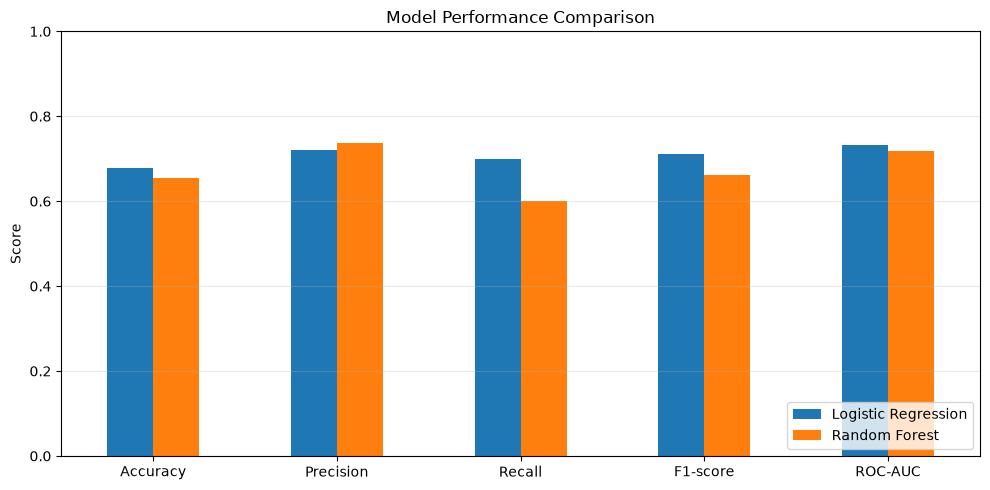

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Logistic Regression": {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    },
    "Random Forest": {
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Precision": precision_score(y_test, rf_pred),
        "Recall": recall_score(y_test, rf_pred),
        "F1-score": f1_score(y_test, rf_pred),
        "ROC-AUC": roc_auc_score(y_test, rf_proba)
    }
})

display(comparison.round(4))

comparison.plot(kind="bar", figsize=(10, 5))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

,Feature,Importance
1,HistoricalRevenue,0.2354
2,HistoricalQuantity,0.2314
4,Recency,0.1958
0,HistoricalOrders,0.1888
3,AverageOrderValue,0.1486


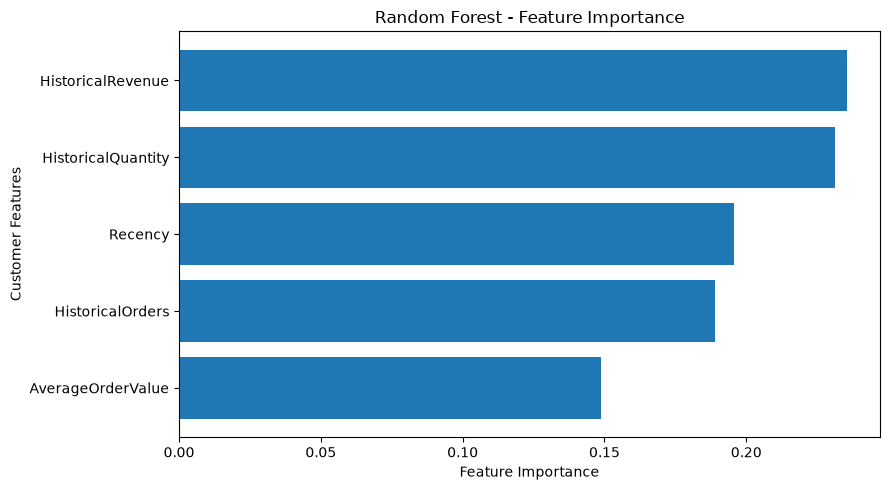

In [31]:
# Extract feature importance from Random Forest
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort from most to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.round(4))

# Visualize feature importance
plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Customer Features")
plt.title("Random Forest - Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [32]:
import joblib
from pathlib import Path

# Create project output folders if needed
models_dir = Path("../models")
reports_dir = Path("../reports")

models_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)

# Save trained models
joblib.dump(logistic_model, models_dir / "repeat_purchase_logistic.pkl")
joblib.dump(rf_model, models_dir / "repeat_purchase_random_forest.pkl")

# Save model comparison
comparison.to_csv(
    reports_dir / "repeat_purchase_model_comparison.csv",
    index=True
)

# Save Random Forest feature importance
feature_importance.to_csv(
    reports_dir / "repeat_purchase_feature_importance.csv",
    index=False
)

print("Models and evaluation reports saved successfully.")
print("Saved files:")
print("- models/repeat_purchase_logistic.pkl")
print("- models/repeat_purchase_random_forest.pkl")
print("- reports/repeat_purchase_model_comparison.csv")
print("- reports/repeat_purchase_feature_importance.csv")

Models and evaluation reports saved successfully.
Saved files:
- models/repeat_purchase_logistic.pkl
- models/repeat_purchase_random_forest.pkl
- reports/repeat_purchase_model_comparison.csv
- reports/repeat_purchase_feature_importance.csv


In [33]:
print("Historical data ends:", historical_data["InvoiceDate"].max())
print("Future data starts:", future_data["InvoiceDate"].min())
print("Future data ends:", future_data["InvoiceDate"].max())

print("\nCurrent cutoff:", cutoff_date)
print("Prediction window ends:", prediction_end)
print("Customers used for modeling:", len(customer_features))

Historical data ends: 2011-08-31 17:16:00
Future data starts: 2011-09-01 08:25:00
Future data ends: 2011-11-29 18:14:00

Current cutoff: 2011-09-01 00:00:00
Prediction window ends: 2011-11-30 00:00:00
Customers used for modeling: 3317


In [34]:
# Check the dataset's date coverage
dataset_start = df_clean["InvoiceDate"].min()
dataset_end = df_clean["InvoiceDate"].max()

print("Dataset start:", dataset_start)
print("Dataset end:", dataset_end)

# Latest cutoff that permits a complete 90-day prediction window
latest_valid_cutoff = dataset_end.normalize() - pd.Timedelta(days=90)

print("Latest cutoff with a full 90-day outcome window:",
      latest_valid_cutoff)

Dataset start: 2010-12-01 08:26:00
Dataset end: 2011-12-09 12:50:00
Latest cutoff with a full 90-day outcome window: 2011-09-10 00:00:00


In [35]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# Baseline: always predict the most frequent training class
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

baseline_pred = dummy_model.predict(X_test)

print("BASELINE MODEL")
print("-" * 30)
print(f"Accuracy: {accuracy_score(y_test, baseline_pred):.4f}")
print(f"F1-score: {f1_score(y_test, baseline_pred, zero_division=0):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, baseline_pred):.4f}")

print("\nLOGISTIC REGRESSION")
print("-" * 30)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"F1-score: {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, y_proba):.4f}")

BASELINE MODEL
------------------------------
Accuracy: 0.5617
F1-score: 0.7194
ROC-AUC:  0.5000

LOGISTIC REGRESSION
------------------------------
Accuracy: 0.6792
F1-score: 0.7102
ROC-AUC:  0.7322


In [36]:
# Create a final evaluation summary
final_evaluation = pd.DataFrame({
    "Model": [
        "Majority Baseline",
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, baseline_pred),
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, baseline_pred, zero_division=0),
        precision_score(y_test, y_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, baseline_pred),
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1_Score": [
        f1_score(y_test, baseline_pred, zero_division=0),
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred)
    ],
    "ROC_AUC": [
        roc_auc_score(y_test, baseline_pred),
        roc_auc_score(y_test, y_proba),
        roc_auc_score(y_test, rf_proba)
    ]
})

display(final_evaluation.round(4))

final_evaluation.to_csv(
    reports_dir / "final_model_evaluation.csv",
    index=False
)

print("Final evaluation report saved successfully.")

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Majority Baseline,0.5617,0.5617,1.0000,0.7194,0.5000
1,Logistic Regression,0.6792,0.7210,0.6997,0.7102,0.7322
2,Random Forest,0.6551,0.7368,0.6005,0.6617,0.7172


Final evaluation report saved successfully.
